## Code Demo of **convert_flux** package
`convert_flux` is a Python package for converting between the brightness quantities used in astronomy: magnitudes (AB, ST, and soon Vega), flux densities, fluxes, and luminosities. You give its single function, `convert_flux()`, an `astropy` Quantity and the unit you want back, and it works out the conversion steps and asks only for the extra information those steps need, such as a filter, a source spectrum shape, or a distance or redshift. Its purpose is to replace hand-written, error-prone conversions (magnitude zero points, filter integrals, luminosity distances) with one consistent, tested tool built on `astropy.units`.

In [38]:
# ! pip install convert_flux
# above installs from PyPI, only if desired package version is published there

# below installs the local version of the package
%pip install -e ..
%xmode Minimal

Obtaining file:///Users/robin/Desktop/TIMESTEP/astro_se_internship/convert_flux
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for convert_flux (pyproject.toml) ... done
  Created wheel for convert_flux: filename=convert_flux-0.3.0-0.editable-py3-none-any.whl size=28427 sha256=5040c3086086297df05d334938efe9fb86b1d746a9d10472dde9462b1ce771c3
  Stored in directory: /private/var/folders/28/y9vvf0dx2jq_3jv34p6bbjdr0000gr/T/pip-ephem-wheel-cache-lrack31s/wheels/a6/31/0d/d79eee44076ed14c73a6d52465c5ce5bca23277b9d147ebb92
Successfully built convert_flux
  Attempting uninstall: convert_flux
    Found existing installation: convert_flux 0.3.0
    Uninstalling convert_flux-0.3.0:
      Successfully uninstalled convert_flux-0.3.0
Note: you may need to restart the kernel to use updated packages.
Exception reporting mode

In [40]:
from convert_flux import convert_flux
import astropy.units as u
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [4]:
# Conversion from 20 ABMag to uJy (flux density freq)
# Direct astropy conversion

abmag = 20 * u.ABmag
desired_flux_density_unit = u.uJy
convert_flux(abmag, desired_flux_density_unit)

# expected_flux_density = 36.31 uJy

<Quantity 36.30780548 uJy>

In [30]:
# Array conversion

abmag_arr = [20, 21, 22] * u.ABmag
desired_flux_density_unit = u.uJy
convert_flux(abmag_arr, desired_flux_density_unit)

<Quantity [36.30780548, 14.45439771,  5.75439937] uJy>

In [32]:
# ST magnitude
desired_magnitude_unit = u.STmag
convert_flux(abmag_arr, desired_magnitude_unit, 
             telescope='SLOAN', 
             instrument = 'SDSS', 
             filter_name = 'r')

<Magnitude [20.26471504, 21.26471504, 22.26471504] mag(ST)>

In [ ]:
# Conversion from 20 ABMag to erg/s/cm^2/AA (flux density wavelength)
# needs filter info:
'''
, 
telescope='SLOAN', 
instrument = 'SDSS', 
filter_name = 'r'
'''

abmag = 20 * u.ABmag
desired_flux_density_unit = u.erg / (u.s * u.cm**2 * u.AA)

convert_flux(abmag, 
             desired_flux_density_unit)

# expected_flux_density ~ 2.845 * 10^-17 erg/s/cm^2/AA

<Quantity 2.84520776e-17 erg / (Angstrom s cm2)>

In [19]:
# What happens when you don't use an astropy quantity or a brightness unit
# TypeError: no unit

convert_flux(20, u.uJy)

TypeError: input_quantity must be an astropy Quantity.

In [20]:
# ValueError: non brightness unit

convert_flux(20 * u.ABmag, u.kg)

ValueError: kg is not a supported brightness unit. Use a magnitude, flux density, flux, or luminosity unit (see conversion_units.rst).

In [ ]:
# Missing requirements error


In [ ]:
# Conversion from 36.31 uJy (flux density) to erg/s/cm^2 (flux)
# needs filter info (sdss r)

flux_density = 36.31 * u.uJy
desired_flux_unit = u.erg / (u.s * u.cm**2)

convert_flux(flux_density, desired_flux_unit, 
             telescope='SLOAN', 
             instrument = 'SDSS', 
             filter_name = 'r')

# expected_flux ~ 1.554 * 10^-14 erg/s/cm^2

<Quantity 1.55398991e-14 erg / (s cm2)>

In [ ]:
# Conversion from 1.554e-14 erg/s/cm^2 (flux) to erg/s (luminosity)
# needs distance = 20 Mpc

flux = 1.554e-14 * u.erg / (u.s * u.cm**2)
desired_luminosity_unit = u.erg / u.s

convert_flux(flux, desired_luminosity_unit, distance = 20 * u.Mpc)

# expected_luminosity ~ 7.437e38 erg/s

<Quantity 7.43741406e+38 erg / s>

In [ ]:
# Conversion from 20 AB mag to erg/s (luminosity) 
# shows full chain from above: AB magnitude -> flux density -> flux -> luminosity

mag = 20 * u.ABmag
desired_luminosity_unit = u.erg / u.s

convert_flux(mag, 
             desired_luminosity_unit, 
             distance = 20 * u.Mpc, 
             instrument = 'SDSS', 
             filter_name = 'r')         # notice telescope is not needed here

# expected_luminosity ~ 7.437e38 erg/s (differs from above due to rounded flux input above)

<Quantity 7.43691627e+38 erg / s>

In [ ]:
# Reverse conversion

convert_flux(7.4369163e38 * u.erg / u.s, u.ABmag,
             distance = 20 * u.Mpc, 
             instrument = 'SDSS', 
             filter_name = 'r')    

<Magnitude 20. mag(AB)>

## Research workflow example:

Magnitudes were obtained in the g and i band at the 90" Bok Telescope at Kitt Peak for an undergraduate observational astronomy class final project. This data is from a Cepheid located in M33, and we used this to calculate the distance to M33 using the standard-candle Cepheid relation.

In [28]:
# Cepheid magnitudes obtained from instrumental counts and zero point calibration, in 
# SDSS g band.

mag_g = [19.757130362147997, 19.62485072593883, 18.86407323134885,
         19.757497282889474, 19.752255636930172, 19.745493677487094, 19.507875958931386,
         19.170324605787584, 18.93010747691001, 19.01757586354041, 19.1017914050386,
         18.983418414567936, 19.089877134355884, 19.137055509855976, 19.349265659499725,
         19.411247971610404, 19.518956507105276, 19.773024858359243, 19.773024858359243, 
         19.70417647955187, 19.674134039784875, 19.62115899893216,
         19.806573714816345] * u.ABmag

Flux Density conversion

In [29]:
desired_flux_density_unit = u.uJy
convert_flux(mag_g, desired_flux_density_unit,
             telescope='BOK',
             instrument = 'BASS',
             filter_name = 'g')

<Quantity [ 45.40961869,  51.29319004, 103.36433322,  45.39427527,
            45.61395662,  45.89892658,  57.12807845,  77.95969972,
            97.26509364,  89.73660907,  83.03925382,  92.60461578,
            83.95549881,  80.38551455,  66.11404609,  62.44545169,
            56.54801925,  44.74969263,  44.74969263,  47.67924922,
            49.01696124,  51.46789431,  43.38808817] uJy>

Flux conversion

In [30]:
desired_flux_unit = u.erg / (u.s * u.cm**2 * u.AA)
convert_flux(mag_g, desired_flux_unit,
             telescope='BOK',
             instrument = 'BASS',
             filter_name = 'g',
            )

<Quantity [5.93651485e-17, 6.70568908e-17, 1.35130820e-16, 5.93450897e-17,
           5.96322847e-17, 6.00048332e-17, 7.46849887e-17, 1.01918697e-16,
           1.27157129e-16, 1.17314950e-16, 1.08559327e-16, 1.21064368e-16,
           1.09757157e-16, 1.05090026e-16, 8.64325726e-17, 8.16365259e-17,
           7.39266626e-17, 5.85024104e-17, 5.85024104e-17, 6.23322942e-17,
           6.40811191e-17, 6.72852862e-17, 5.67223503e-17] erg / (Angstrom s cm2)>

Using convert_flux, we'll use the calculated luminosities and following the distance calculation of our project using the methodology we followed: [ASTR302 Final Project](https://docs.google.com/presentation/d/1YUwqKP7aKTKYxKnlX1pxcjfpUcOeo0eYIFld0loa02U/edit?usp=sharing)

In [ ]:
desired_luminosity_unit = u.erg / u.s
luminosities_g = convert_flux(mag_g[:, None], desired_luminosity_unit,
             telescope='BOK',
             instrument = 'BASS',
             filter_name = 'g',
             distance = 0.828 * u.Mpc # distance to M33, calculated from our method.
            )

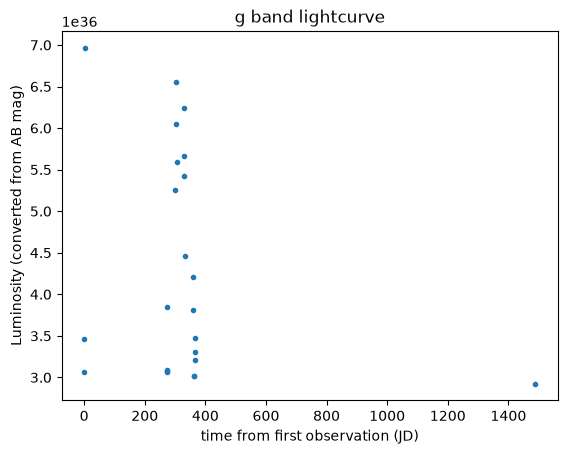

In [ ]:
# Time of observations in Julian Date (JD) for the g band lightcurve, using both archival data in 2022 and new observations in Feb 2026. 
# The time is relative to the first observation.

time_JD_g = [2459606.6, 2459607.6, 2459610.6,
             2459878.6, 2459879.6, 2459880.7, 2459881.6,
             2459907.6, 2459909.5, 2459910.5, 2459911.6,
             2459935.5, 2459936.6, 2459937.6, 2459940.5,
             2459965.6, 2459966.6, 2459970.6, 2459970.6, 2459971.6, 2459972.6, 2459973.6,
             2461094.6]

time_g = np.array(time_JD_g)
time_g = time_g - time_g[0]

plt.plot(time_g,luminosities_g,'.')
plt.title('g band lightcurve')
plt.xlabel('time from first observation (JD)')
plt.ylabel('Luminosity (converted from AB mag)')
plt.show()

Following similarly to using g-band magnitudes, we will then apply a sawtooth fit to the lightcurve to extract the period of the Cepheid, which is used for our distance calculation. Code is adopted from our original group project.

In [ ]:
from scipy.optimize import differential_evolution
from scipy.signal import sawtooth

# Convert to arrays
time_JD_g = np.array(time_JD_g, dtype=float)
luminosities_g = np.array(luminosities_g, dtype=float)

# Set t0
t = time_JD_g - time_JD_g[0]
y = luminosities_g.copy()

# Set this to False if you do not want the 2026 point included in the fit
use_2026_point = True

fix = np.isfinite(t) & np.isfinite(y)

if not use_2026_point:
    fix = fix & (t < 500)

t_fit = t[fix]
y_fit = y[fix]

# Average points with the exact same time so one duplicate night does not get overweighted
t_unique = []
y_unique = []

for tt in np.unique(t_fit):
    same_time = np.isclose(t_fit, tt)
    t_unique.append(tt)
    y_unique.append(np.mean(y_fit[same_time]))

t_fit = np.array(t_unique)
y_fit = np.array(y_unique)

def solve_amp_offset(t, y, P, phase_frac, width):
    phase = phase_frac * P

    shape = sawtooth(2 * np.pi * (t - phase) / P, width=width)

    # Fit y = offset + amp * shape
    X = np.column_stack([np.ones_like(shape), shape])
    offset, amp = np.linalg.lstsq(X, y, rcond=None)[0]

    model = offset + amp * shape
    return offset, amp, model

def objective(params):
    P, phase_frac, width = params

    offset, amp, model = solve_amp_offset(t_fit, y_fit, P, phase_frac, width)
    residuals = y_fit - model

    return np.sum(residuals**2)

# Bounds:
# P is Cepheid period in days
# phase_frac is phase as a fraction of the period
# width controls the sawtooth asymmetry
bounds = [
    (5, 80),       # period range in days
    (0, 1),        # phase fraction
    (0.05, 0.95)   # sawtooth width
]

# Try multiple random seeds so the fit is less likely to get stuck
best_result = None

for seed in range(8):
    result = differential_evolution(
        objective,
        bounds=bounds,
        seed=seed,
        maxiter=200,
        popsize=20,
        tol=1e-8,
        polish=True
    )

    if best_result is None or result.fun < best_result.fun:
        best_result = result

P_best, phase_frac_best, width_best = best_result.x
phase_best = phase_frac_best * P_best

offset_best, amp_best, model_fit = solve_amp_offset(
    t_fit, y_fit, P_best, phase_frac_best, width_best
)

rmse = np.sqrt(np.mean((y_fit - model_fit)**2))

print("Best-fit parameters:")
print("Period =", P_best)
print("Phase =", phase_best)
print("Width =", width_best)
print("Offset =", offset_best)
print("Amplitude parameter =", amp_best)
print("Peak-to-peak amplitude =", 2 * abs(amp_best))
print("RMSE =", rmse)

P_g_best = P_best

Best-fit parameters:
Period = 22.89772461346517
Phase = 4.344435474981141
Width = 0.787143937445622
Offset = 4.6974861391939925e+36
Amplitude parameter = -1.901156317033073e+36
Peak-to-peak amplitude = 3.802312634066146e+36
RMSE = 3.1521890292858645e+35


We obtain the same period using the calculated luminosities from `convert_flux`. This is one simple use case to interpret our data with other measurable quantities. In the future, vega spec integration will be applied to `convert_flux` such that our derived magnitues are more accurate and reliable.

Plotting our data to visualize the lightcurve and best sawtooth fit:

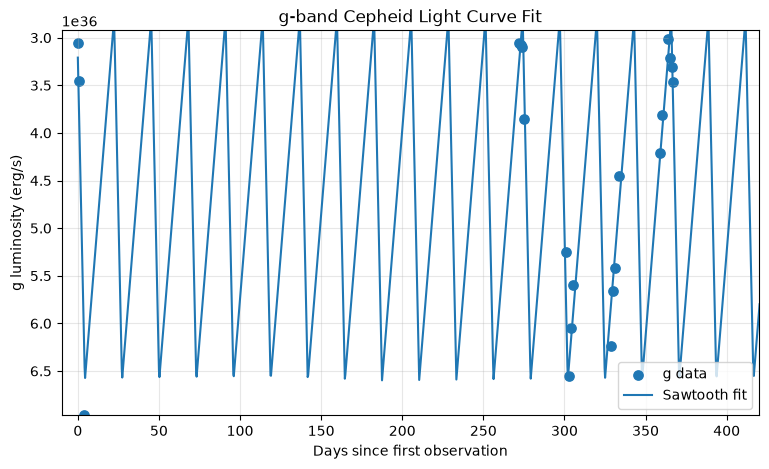

In [56]:
def g_saw_model(t):
    shape = sawtooth(2 * np.pi * (t - phase_best) / P_best, width=width_best)
    return offset_best + amp_best * shape
# Plot 1 time domain plot, zoomed to the 2022-2023 section (or its stretched)

t_smooth = np.linspace(np.min(t_fit), np.max(t_fit), 5000)
mag_smooth = g_saw_model(t_smooth)

plt.figure(figsize=(9, 5))

plt.scatter(t_fit, y_fit, s=45, label="g data")
plt.plot(t_smooth, mag_smooth, label="Sawtooth fit")

plt.xlabel("Days since first observation")
plt.ylabel("g luminosity (erg/s)")
plt.title("g-band Cepheid Light Curve Fit")

# Zoom to the useful part of the data
plt.xlim(-10, 420)
plt.ylim(np.max(y_fit) + 0.1, np.min(y_fit) - 0.1)

plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

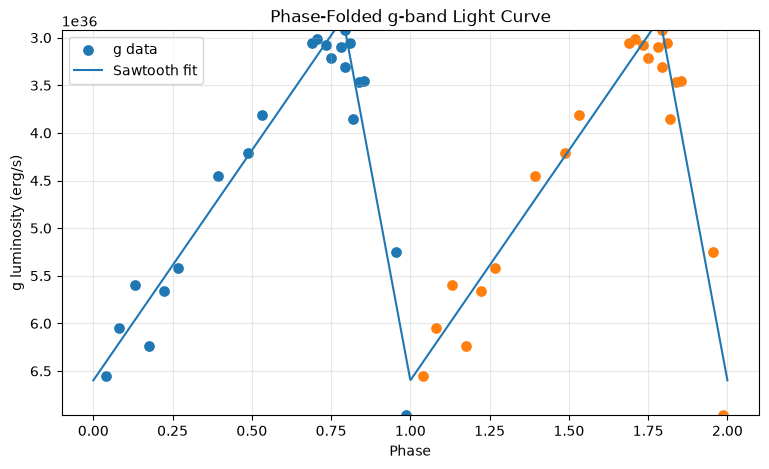

In [57]:
# Plot 2 phase folded light curve
phase = ((t_fit - phase_best) / P_best) % 1

phase_plot = np.linspace(0, 2, 1000)
model_phase = offset_best + amp_best * sawtooth(2 * np.pi * phase_plot, width=width_best)

plt.figure(figsize=(9, 5))

plt.scatter(phase, y_fit, s=45, label="g data")
plt.scatter(phase + 1, y_fit, s=45)

plt.plot(phase_plot, model_phase, label="Sawtooth fit")

plt.xlabel("Phase")
plt.ylabel("g luminosity (erg/s)")
plt.title("Phase-Folded g-band Light Curve")

plt.ylim(np.max(y_fit) + 0.1, np.min(y_fit) - 0.1)

plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

P_g_best = P_best